In [21]:
import mlflow
import dagshub

dagshub.init(repo_name = 'yt_chrome_plugin', repo_owner = 'AmanGupta8423', mlflow = True)
mlflow.set_experiment("Baseline Model")
mlflow.set_tracking_uri('https://dagshub.com/AmanGupta8423/yt_chrome_plugin.mlflow')


Accessing as AmanGupta8423

Initialized MLflow to track repo "AmanGupta8423/yt_chrome_plugin"

Repository AmanGupta8423/yt_chrome_plugin initialized!

In [18]:
import numpy as np
import pandas as pd
import nltk
from nltk.corpus import stopwords
import re
from nltk.stem import WordNetLemmatizer
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/Himanshu-1703/reddit-sentiment-analysis/refs/heads/main/data/reddit.csv')

In [4]:
df.dropna(inplace = True)

C:\Users\win11\AppData\Local\Temp\ipykernel_11188\1791587065.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace = True)


In [5]:
df.drop_duplicates(inplace=True)

C:\Users\win11\AppData\Local\Temp\ipykernel_11188\3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [6]:
df = df[~(df['clean_comment'].str.strip() == '')]
# df['clean_comment'] = df['clean_comment'].str.lower()
# df['clean_comment'] = df['clean_comment'].str.strip()
# df['clean_comment'] = df['clean_comment'].str.replace('\n',' ',regex=True)

In [7]:
nltk.download('stopwords')
nltk.download('wordnet')

lematizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english')) - {'not', 'but', 'however', 'no', 'yet'}

def process_comment(comment):
    comment = comment.lower()
    comment = comment.strip()
    comment = re.sub(r'\n',' ',comment)

    comment = re.sub(r'[^A-Za-z0-9\s!?.,]','',comment)

    
    comment = ' '.join([word for word in comment.split() if word.lower() not in stop_words])

    
    comment = ' '.join([lematizer.lemmatize(word) for word in comment.split()])

    return comment

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\win11\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\win11\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [8]:
df['clean_comment'] = df['clean_comment'].apply(process_comment)

In [9]:
df.head()

,clean_comment,category
0,family mormon never tried explain still stare ...,1
1,buddhism much lot compatible christianity espe...,1
2,seriously say thing first get complex explain ...,-1
3,learned want teach different focus goal not wr...,0
4,benefit may want read living buddha living chr...,1


In [ ]:
# df['word_count'] = df['clean_comment'].apply(lambda x:len(x.split()))


# # nltk.download('stopwords')

# stop_words= set(stopwords.words('english'))
# df['num_stop_words'] = df['clean_comment'].apply(lambda x: len([word for word in x.split() if word in stop_words]))

# df['num_char'] = df['clean_comment'].apply(len)

# df['num_punctuation_chars'] = df['clean_comment'].apply(lambda x: sum([1 for char in x if char in '.,!?;:"\'()[]{}-']))

# # df['clean_comment'] = df['clean_comment'].apply(lambda x: re.sub(r'[^A-Za-z0-9\s!?.,]','',str(x)))

# # stop_words = set(stopwords.words('english')) - {'not', 'but', 'however', 'no', 'yet'}

# # df['clean_comment'] = df['clean_comment'].apply(lambda x: ' '.join([word for word in x.split() if word.lower() not in stop_words]))

# # nltk.download('wordnet')
# # lemitizer = WordNetLemmatizer()

# # df['clean_comment'] = df['clean_comment'].apply(lambda x: ' '.join([lemitizer.lemmatize(word) for word in x.split()]))


In [14]:
vectorizer = CountVectorizer(max_features=5000)
X = vectorizer.fit_transform(df['clean_comment']).toarray()
y = df['category']

In [15]:
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(36793, 5000))

In [16]:
y

0        1
1        1
2       -1
3        0
4        1
        ..
37244    0
37245    1
37246    0
37247    1
37248    0
Name: category, Length: 36793, dtype: int64

🏃 View run RandomForestClassifier_baseline at: https://dagshub.com/AmanGupta8423/yt_chrome_plugin.mlflow/#/experiments/1/runs/81a08ce1fd73466b9ef81c84fb5148b3
🧪 View experiment at: https://dagshub.com/AmanGupta8423/yt_chrome_plugin.mlflow/#/experiments/1
Accuracy: 0.6359559722788423


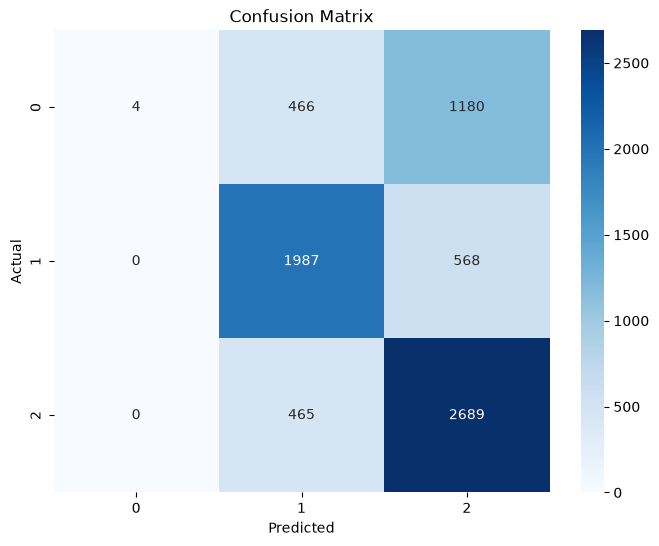

In [25]:
X_train,X_test,y_train,y_test = train_test_split(X,y, test_size= 0.2,random_state = 42,stratify=y)

with mlflow.start_run() as run:
    mlflow.set_tag('mlflow.runName', 'RandomForestClassifier_baseline')
    mlflow.set_tag('experiment_type', 'baseline')
    mlflow.set_tag('model_type','RandomForestClassifier')

    mlflow.set_tag('description','Baseline model foe sentiment analysis using Bag of Words with simple train_test_split')

    mlflow.log_param('vectorize_text','CountVectorizer')
    mlflow.log_param('vectorizer_max_features',vectorizer.max_features)

    n_estimators = 100
    max_depth = 10

    mlflow.log_param('n_estimators',n_estimators)
    mlflow.log_param('max_depth',max_depth)

    model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth,random_state=42)
    model.fit(X_train,y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test,y_pred)

    classification_rep = classification_report(y_test,y_pred,output_dict=True)

    for label,metrics in classification_rep.items():
        if isinstance(metrics, dict):
            for metric, value in metrics.items():
                mlflow.log_metric(f'{label}_{metric}',value)

    conf_matrix = confusion_matrix(y_test,y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(conf_matrix,annot = True, fmt = 'd',cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')

    os.makedirs("./reports", exist_ok=True)
    os.makedirs("./data/raw", exist_ok=True)

    plt.savefig('./reports/confusion_matrix.png')
    mlflow.log_artifact('./reports/confusion_matrix.png')

    mlflow.sklearn.log_model(model, name="random_forest_model",skops_trusted_types=["sklearn.tree._tree.Tree"])

    df.to_csv('./data/raw/dataset.csv',index = False)
    mlflow.log_artifact('./data/raw/dataset.csv')

print(f'Accuracy: {accuracy}')


In [24]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

          -1       1.00      0.00      0.00      1650
           0       0.68      0.78      0.73      2555
           1       0.61      0.85      0.71      3154

    accuracy                           0.64      7359
   macro avg       0.76      0.54      0.48      7359
weighted avg       0.72      0.64      0.56      7359

